# Gene expression heatmap by patient, tissue and cancer annotation

Uses the completed 7% per-slide sample: **66,787 patches, 32 shared genes, 421 slides**.
No downloads, patch extraction, or image-tensor loading are needed.

Outputs include a complete interactive patch heatmap, a patient-mean overview,
readable patch pages, and exact start/end column tables. Known patient labels
are scoped to their dataset; missing IDs stay as separate slides rather than
being falsely combined into one patient.

## 1. Setup and saved data

If needed, install `JamesExperiment/requirements.txt` in the project environment.

In [1]:
from pathlib import Path
import sys, json, os, re, base64
import numpy as np
import pandas as pd
import torch
from IPython.display import display, Image, FileLink

here = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in (here, *here.parents)
                     if (p / 'JamesExperiment' / 'gene_heatmap.py').is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('Start Jupyter inside this project.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from JamesExperiment.gene_heatmap import create_heatmaps, build_annotations

TENSOR_DIR = PROJECT_ROOT / 'outputs/JamesExperiment/compact_patches_7_seed_42'
METADATA_CSV = PROJECT_ROOT / 'outputs/JamesExperiment/selection/selected_metadata.csv'
OUTPUT_DIR = PROJECT_ROOT / 'outputs/JamesExperiment/gene_expression_heatmap_7pct'
PATIENTS_PER_PAGE = 16
PATIENT_MAP_PATH = None  # Optional CSV: slide_id,patient_id, with globally unique patient IDs.
print('Targets:', TENSOR_DIR / 'targets.pt')
print('Heatmap outputs:', OUTPUT_DIR)

Targets: C:\Users\22708\Documents\BME_DataDesign\Hist2ST\Hist2ST\outputs\JamesExperiment\compact_patches_7_seed_42\targets.pt
Heatmap outputs: C:\Users\22708\Documents\BME_DataDesign\Hist2ST\Hist2ST\outputs\JamesExperiment\gene_expression_heatmap_7pct


## 2. Review patient and disease metadata

**P codes** represent known patient labels scoped to their source dataset.
**S codes** mean the patient ID is unknown; that slide is displayed separately.
S boundaries cannot be interpreted as confirmed biological patient boundaries.

Cancer annotation is based on **slide-level metadata**, not a tumor prediction
for every patch. Cancer = cancerous annotation; Healthy = no cancer annotation;
Tumor = malignancy unspecified; Diseased/Treated = unknown. Exact disease states
are also shown separately.

In [2]:
manifest = pd.read_csv(TENSOR_DIR / 'patch_manifest.csv')
metadata = pd.read_csv(METADATA_CSV, dtype=str).fillna('')
slides, ordered, boundaries = build_annotations(manifest, metadata, PATIENT_MAP_PATH)
print('Slides:', len(slides))
print('Known patient groups:', int(boundaries.patient_id_known.sum()))
print('Unknown-patient slide groups:', int((~boundaries.patient_id_known).sum()))
display(slides.groupby(['disease_state', 'cancer_annotation'], dropna=False).size().rename('slides').reset_index())
display(boundaries[['group_code','patient_label','start_column_1based','end_column_1based_inclusive',
                    'patch_count','organs','tissues','disease_states','cancer_annotations']].head(15))

Slides: 421
Known patient groups: 81
Unknown-patient slide groups: 302


,disease_state,cancer_annotation,slides
0,Cancer,Cancer,172
1,Diseased,Unknown / not specified,114
2,Healthy,Healthy / no cancer annotation,102
3,Treated,Unknown / not specified,26
4,Tumor,Tumor / malignancy unspecified,7


,group_code,patient_label,start_column_1based,end_column_1based_inclusive,patch_count,organs,tissues,disease_states,cancer_annotations
0,P001,P001 | Patient 1,1,53,53,Bladder,Bladder,Cancer,Cancer
1,P002,P002 | Patient 2,54,121,68,Bladder,Bladder,Cancer,Cancer
2,P003,P003 | Patient 3,122,223,102,Bladder,Bladder,Cancer,Cancer
3,P004,P004 | Patient 4,224,278,55,Bladder,Bladder,Cancer,Cancer
4,P005,P005 | Patient 1,279,326,48,Bladder,FFPE bladder tumor,Cancer,Cancer
5,P006,P006 | Patient 10,327,426,100,Bladder,Bladder,Cancer,Cancer
6,S001,S001 | MISC33 (ID unknown),427,662,236,Bowel,Colon,Cancer,Cancer
7,S002,S002 | MISC34 (ID unknown),663,921,259,Bowel,Colon,Cancer,Cancer
8,S003,S003 | MISC35 (ID unknown),922,1167,246,Bowel,Colon,Cancer,Cancer
9,S004,S004 | MISC36 (ID unknown),1168,1410,243,Bowel,Colon,Cancer,Cancer


## 3. Render heatmaps and patient boundaries

Rows are genes. Patch columns are reordered so every patient group is contiguous,
then ordered by slide and original tensor row within a group. White lines mark
group starts and ends. The original tensor is unchanged; patch_annotations.csv
maps every heatmap column back to its tensor row, slide, patch and barcode.

Colors show a per-gene z-score of `log1p(raw expression)`, clipped to ±2.5 for
display only. Constant genes are shown at zero. No library-size normalization
is computed from the limited 32-gene panel. Hover displays unmodified counts.
The overview averages these display values within each patient group;
the interactive heatmap and PNG pages retain individual patch values.

In [3]:
summary = create_heatmaps(
    TENSOR_DIR, METADATA_CSV, OUTPUT_DIR,
    patients_per_page=PATIENTS_PER_PAGE, patient_map_path=PATIENT_MAP_PATH,
)
display(pd.Series(summary, name='Heatmap run'))

Rendered patient page 1: 16 groups, 2,647 patches


Rendered patient page 2: 16 groups, 2,721 patches


Rendered patient page 3: 16 groups, 3,471 patches


Rendered patient page 4: 16 groups, 4,042 patches


Rendered patient page 5: 16 groups, 5,679 patches


Rendered patient page 6: 16 groups, 2,719 patches


... (16 outputs left out)

Rendered patient page 23: 16 groups, 852 patches


Rendered patient page 24: 15 groups, 1,179 patches


{
  "complete": true,
  "patches": 66787,
  "genes": 32,
  "slides": 421,
  "known_patient_groups": 81,
  "unknown_patient_slide_groups": 302,
  "slides_with_known_patient": 119,
  "page_count": 24,
  "patients_per_page": 16,
  "color_scale": "per-gene z-score of log1p(raw expression), clipped at +/-2.5",
  "patient_scope": "dataset title + patient ID; missing patient ID remains a separate slide",
  "cancer_policy": "Cancer=yes; Healthy=no cancer annotation; Tumor=malignancy unspecified; Diseased/Treated=unknown",
  "target_sha256": "e5036632763b02b718b8f162b345757edc391b50d91620f8e72951f74518f9ed",
  "source_tensor_dir": "C:\\Users\\22708\\Documents\\BME_DataDesign\\Hist2ST\\Hist2ST\\outputs\\JamesExperiment\\compact_patches_7_seed_42"
}


complete                                                                     True
patches                                                                     66787
genes                                                                          32
slides                                                                        421
known_patient_groups                                                           81
unknown_patient_slide_groups                                                  302
slides_with_known_patient                                                     119
page_count                                                                     24
patients_per_page                                                              16
color_scale                     per-gene z-score of log1p(raw expression), cli...
patient_scope                   dataset title + patient ID; missing patient ID...
cancer_policy                   Cancer=yes; Healthy=no cancer annotation; Tumo...
target_sha256   

## 4. Patient-mean overview

One column per patient / unknown-ID slide group. The paged patch plots and
interactive viewer below show the underlying patch columns and detailed labels.

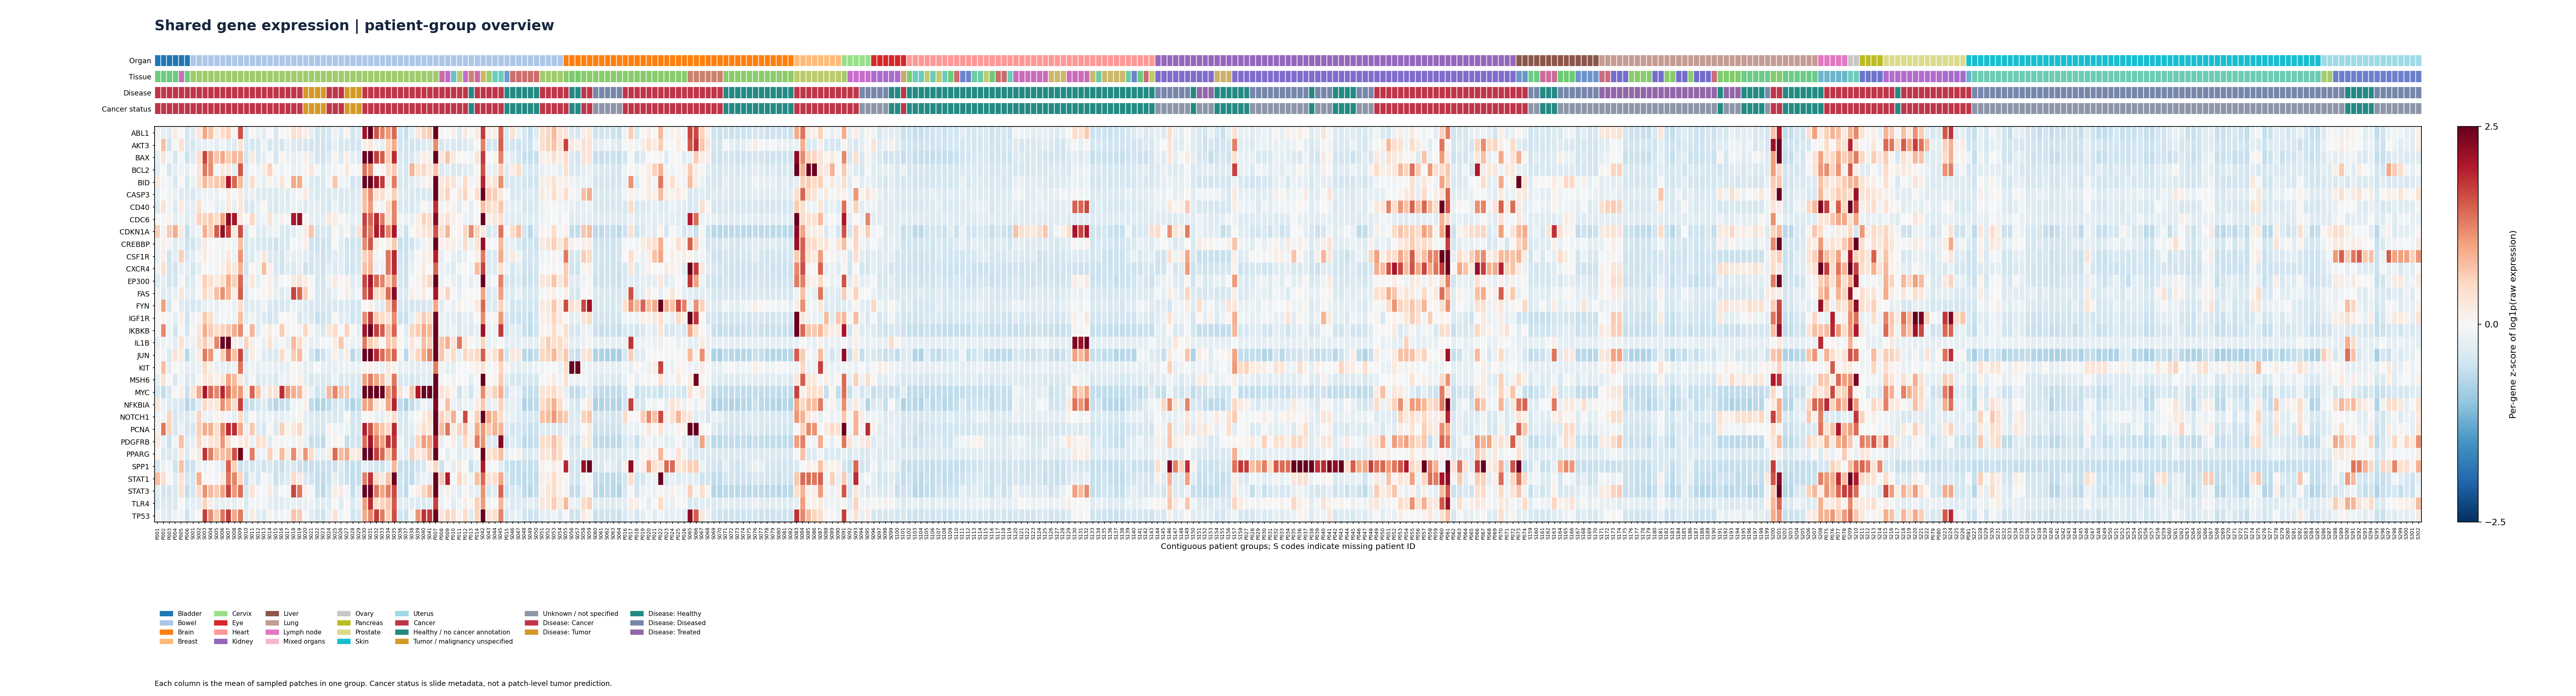

In [4]:
display(Image(filename=str(OUTPUT_DIR / 'patient_mean_overview.png'), width=1600))

## 5. Patch-level example page

Each page contains up to 16 groups. All pages are saved under patient_pages/.
The interactive file includes every patch and every tissue annotation, with
patient selection, range controls, hover details, and a searchable boundary table.

Patch-level pages: 24


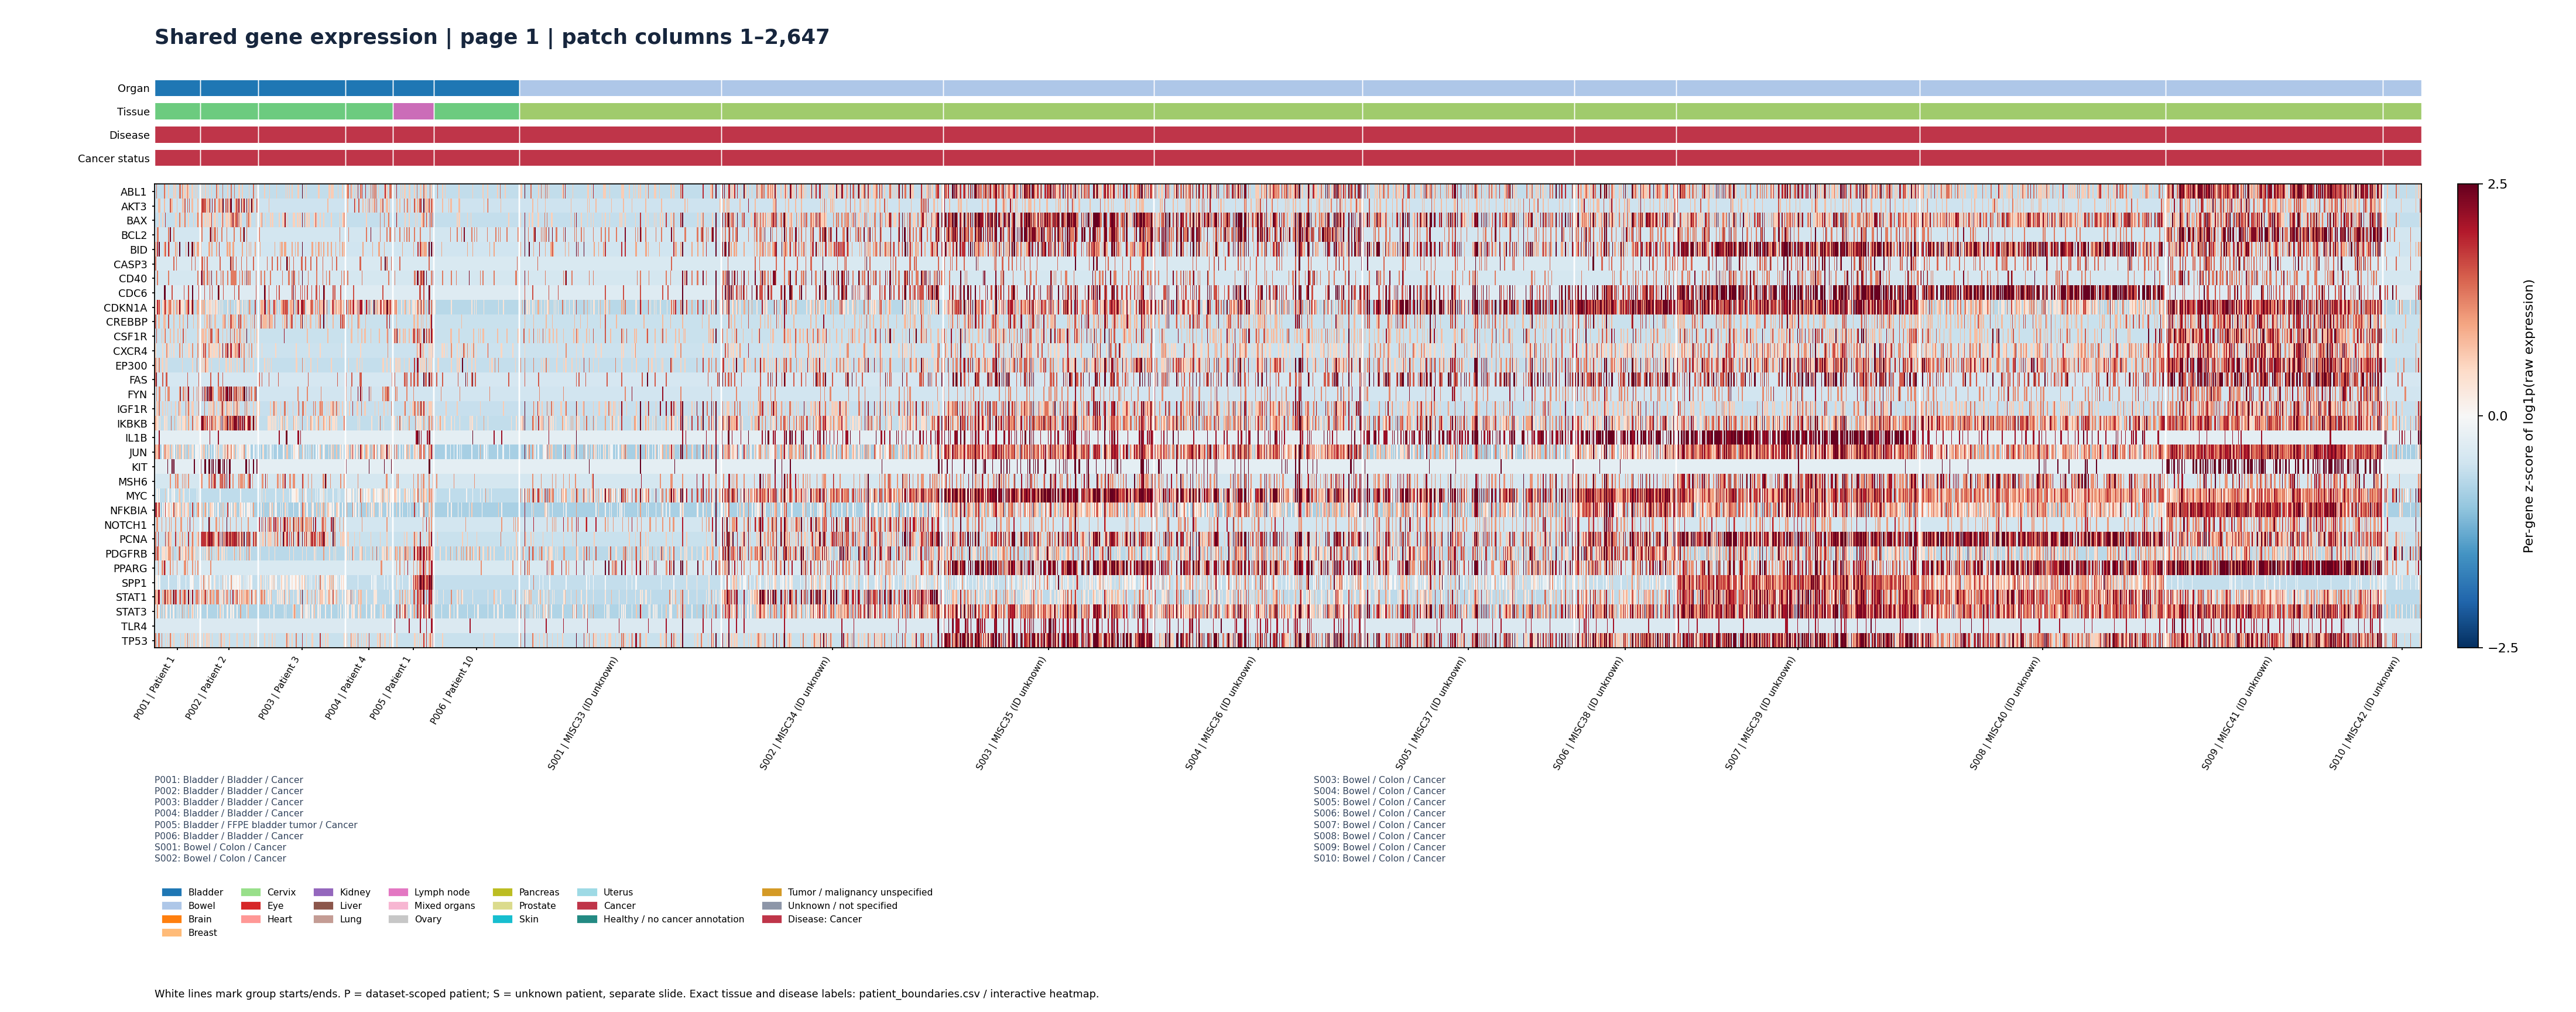

C:\Users\22708\Documents\BME_DataDesign\Hist2ST\Hist2ST\outputs\JamesExperiment\gene_expression_heatmap_7pct\gene_expression_heatmap.html


C:\Users\22708\Documents\BME_DataDesign\Hist2ST\outputs\JamesExperiment\gene_expression_heatmap_7pct\gene_expression_heatmap.html

C:\Users\22708\Documents\BME_DataDesign\Hist2ST\Hist2ST\outputs\JamesExperiment\gene_expression_heatmap_7pct\patient_boundaries.csv


C:\Users\22708\Documents\BME_DataDesign\Hist2ST\outputs\JamesExperiment\gene_expression_heatmap_7pct\patient_boundaries.csv

C:\Users\22708\Documents\BME_DataDesign\Hist2ST\Hist2ST\outputs\JamesExperiment\gene_expression_heatmap_7pct\slide_annotations.csv


C:\Users\22708\Documents\BME_DataDesign\Hist2ST\outputs\JamesExperiment\gene_expression_heatmap_7pct\slide_annotations.csv

C:\Users\22708\Documents\BME_DataDesign\Hist2ST\Hist2ST\outputs\JamesExperiment\gene_expression_heatmap_7pct\patch_annotations.csv


C:\Users\22708\Documents\BME_DataDesign\Hist2ST\outputs\JamesExperiment\gene_expression_heatmap_7pct\patch_annotations.csv

C:\Users\22708\Documents\BME_DataDesign\Hist2ST\Hist2ST\outputs\JamesExperiment\gene_expression_heatmap_7pct\heatmap_summary.json


C:\Users\22708\Documents\BME_DataDesign\Hist2ST\outputs\JamesExperiment\gene_expression_heatmap_7pct\heatmap_summary.json

In [5]:
pages = sorted((OUTPUT_DIR / 'patient_pages').glob('patient_page_*.png'))
print('Patch-level pages:', len(pages))
display(Image(filename=str(pages[0]), width=1600))
for filename in ['gene_expression_heatmap.html', 'patient_boundaries.csv',
                 'slide_annotations.csv', 'patch_annotations.csv', 'heatmap_summary.json']:
    print(OUTPUT_DIR / filename)
    display(FileLink(os.path.relpath(OUTPUT_DIR / filename, PROJECT_ROOT / 'JamesExperiment')))

## 6. Verify coverage, boundaries, and embedded expression values

Checks that all 66,787 patches occur exactly once, patient ranges are contiguous,
metadata coverage matches the source cohort, and the complete interactive matrix
contains the original tensor values in the documented reordered row positions.

In [6]:
saved = json.loads((OUTPUT_DIR / 'heatmap_summary.json').read_text())
patches = pd.read_csv(OUTPUT_DIR / 'patch_annotations.csv', low_memory=False)
groups = pd.read_csv(OUTPUT_DIR / 'patient_boundaries.csv')
genes = json.loads((TENSOR_DIR / 'genes.json').read_text())
targets = torch.load(TENSOR_DIR / 'targets.pt', weights_only=True, map_location='cpu').numpy()
assert saved['complete']
assert len(patches) == len(targets) == len(manifest)
assert sorted(patches.tensor_row.tolist()) == list(range(len(targets)))
assert set(patches.slide_id) == set(manifest.slide_id)
assert groups.patch_count.sum() == len(targets)
assert groups.start_index_0based.iloc[0] == 0
assert groups.end_index_0based_exclusive.iloc[-1] == len(targets)
np.testing.assert_array_equal(groups.start_index_0based.iloc[1:], groups.end_index_0based_exclusive.iloc[:-1])
html = (OUTPUT_DIR / 'gene_expression_heatmap.html').read_text(encoding='utf-8')
payload = json.loads(re.search(r'<script id="heatmap-data" type="application/json">(.*?)</script>', html, re.S).group(1))
embedded = np.frombuffer(base64.b64decode(payload['expression_b64']), dtype='<f4').reshape(len(genes), len(targets)).T
np.testing.assert_array_equal(embedded, targets[patches.tensor_row.to_numpy()])
assert len(pages) == saved['page_count']
verification = dict(verified=True, patches=len(patches), genes=len(genes), slides=patches.slide_id.nunique(),
                    known_patient_groups=int(groups.patient_id_known.sum()),
                    unknown_patient_slide_groups=int((~groups.patient_id_known).sum()),
                    contiguous_boundaries=True, embedded_expression_matches_tensor=True)
(OUTPUT_DIR / 'heatmap_verification.json').write_text(json.dumps(verification, indent=2), encoding='utf-8')
display(verification)
print('Heatmap generation and verification completed.')

{'verified': True,
 'patches': 66787,
 'genes': 32,
 'slides': 421,
 'known_patient_groups': 81,
 'unknown_patient_slide_groups': 302,
 'contiguous_boundaries': True,
 'embedded_expression_matches_tensor': True}

Heatmap generation and verification completed.
